In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay)

sns.set_style("whitegrid")
pd.set_option("display.max_columns", None)   # show all columns

In [2]:
df = pd.read_excel("E Commerce Dataset.xlsx", sheet_name="E Comm")
df.head()

,CustomerID,Churn,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,PreferredPaymentMode,Gender,HourSpendOnApp,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount
0,50001,1,4.0,Mobile Phone,3,6.0,Debit Card,Female,3.0,3,Laptop & Accessory,2,Single,9,1,11.0,1.0,1.0,5.0,159.93
1,50002,1,NaN,Phone,1,8.0,UPI,Male,3.0,4,Mobile,3,Single,7,1,15.0,0.0,1.0,0.0,120.90
2,50003,1,NaN,Phone,1,30.0,Debit Card,Male,2.0,4,Mobile,3,Single,6,1,14.0,0.0,1.0,3.0,120.28
3,50004,1,0.0,Phone,3,15.0,Debit Card,Male,2.0,4,Laptop & Accessory,5,Single,8,0,23.0,0.0,1.0,3.0,134.07
4,50005,1,0.0,Phone,1,12.0,CC,Male,NaN,3,Mobile,5,Single,3,0,11.0,1.0,1.0,3.0,129.60


In [3]:
print("Rows, Columns:", df.shape)
print()
df.info()

Rows, Columns: (5630, 20)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5630 entries, 0 to 5629
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   CustomerID                   5630 non-null   int64  
 1   Churn                        5630 non-null   int64  
 2   Tenure                       5366 non-null   float64
 3   PreferredLoginDevice         5630 non-null   object 
 4   CityTier                     5630 non-null   int64  
 5   WarehouseToHome              5379 non-null   float64
 6   PreferredPaymentMode         5630 non-null   object 
 7   Gender                       5630 non-null   object 
 8   HourSpendOnApp               5375 non-null   float64
 9   NumberOfDeviceRegistered     5630 non-null   int64  
 10  PreferedOrderCat             5630 non-null   object 
 11  SatisfactionScore            5630 non-null   int64  
 12  MaritalStatus                5630 non-null   obje

In [4]:
# Summary of the numeric columns
df.describe().T

,count,mean,std,min,25%,50%,75%,max
CustomerID,5630.0,52815.500000,1625.385339,50001.0,51408.25,52815.50,54222.7500,55630.00
Churn,5630.0,0.168384,0.374240,0.0,0.00,0.00,0.0000,1.00
Tenure,5366.0,10.189899,8.557241,0.0,2.00,9.00,16.0000,61.00
CityTier,5630.0,1.654707,0.915389,1.0,1.00,1.00,3.0000,3.00
WarehouseToHome,5379.0,15.639896,8.531475,5.0,9.00,14.00,20.0000,127.00
HourSpendOnApp,5375.0,2.931535,0.721926,0.0,2.00,3.00,3.0000,5.00
NumberOfDeviceRegistered,5630.0,3.688988,1.023999,1.0,3.00,4.00,4.0000,6.00
SatisfactionScore,5630.0,3.066785,1.380194,1.0,2.00,3.00,4.0000,5.00
NumberOfAddress,5630.0,4.214032,2.583586,1.0,2.00,3.00,6.0000,22.00
Complain,5630.0,0.284902,0.451408,0.0,0.00,0.00,1.0000,1.00


In [5]:
# How many customers churned? (1 = churned, 0 = stayed)
print(df["Churn"].value_counts())
print()
print((df["Churn"].value_counts(normalize=True) * 100).round(1))

Churn
0    4682
1     948
Name: count, dtype: int64

Churn
0    83.2
1    16.8
Name: proportion, dtype: float64


In [6]:
# Missing values: which columns have blanks and how many?
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
pd.DataFrame({"missing_count": missing,
              "missing_%": (missing / len(df) * 100).round(1)})

,missing_count,missing_%
DaySinceLastOrder,307,5.5
OrderAmountHikeFromlastYear,265,4.7
Tenure,264,4.7
OrderCount,258,4.6
CouponUsed,256,4.5
HourSpendOnApp,255,4.5
WarehouseToHome,251,4.5


In [7]:
#  Duplicate rows
print("Duplicate rows before:", df.duplicated().sum())
df = df.drop_duplicates()
print("Duplicate rows after :", df.duplicated().sum())

# Irrelevant column: CustomerID is just a label, it does not help prediction
df = df.drop(columns=["CustomerID"])
print("New shape:", df.shape)

Duplicate rows before: 0
Duplicate rows after : 0
New shape: (5630, 19)


In [8]:
#Same thing written in different ways -> make them one label
cat_cols_check = ["PreferredLoginDevice", "PreferredPaymentMode",
                  "PreferedOrderCat", "Gender", "MaritalStatus"]
for col in cat_cols_check:
    print(col, "->", df[col].unique())

PreferredLoginDevice -> ['Mobile Phone' 'Phone' 'Computer']
PreferredPaymentMode -> ['Debit Card' 'UPI' 'CC' 'Cash on Delivery' 'E wallet' 'COD' 'Credit Card']
PreferedOrderCat -> ['Laptop & Accessory' 'Mobile' 'Mobile Phone' 'Others' 'Fashion' 'Grocery']
Gender -> ['Female' 'Male']
MaritalStatus -> ['Single' 'Divorced' 'Married']


In [9]:
#Merge the repeated labels
df["PreferredLoginDevice"] = df["PreferredLoginDevice"].replace({"Phone": "Mobile Phone"})
df["PreferredPaymentMode"] = df["PreferredPaymentMode"].replace(
    {"CC": "Credit Card", "COD": "Cash on Delivery"})
df["PreferedOrderCat"] = df["PreferedOrderCat"].replace({"Mobile": "Mobile Phone"})

# Check again - the repeated names should be gone
for col in cat_cols_check:
    print(col, "->", df[col].unique())

PreferredLoginDevice -> ['Mobile Phone' 'Computer']
PreferredPaymentMode -> ['Debit Card' 'UPI' 'Credit Card' 'Cash on Delivery' 'E wallet']
PreferedOrderCat -> ['Laptop & Accessory' 'Mobile Phone' 'Others' 'Fashion' 'Grocery']
Gender -> ['Female' 'Male']
MaritalStatus -> ['Single' 'Divorced' 'Married']


In [10]:
#Outliers: count values far away from the rest using the IQR rule
num_check = df.select_dtypes(include="number").columns.drop(["Churn"])

rows = []
for col in num_check:
    q1, q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((df[col] < low) | (df[col] > high)).sum()
    rows.append([col, n_out, round(n_out / len(df) * 100, 1)])

pd.DataFrame(rows, columns=["column", "outlier_count", "outlier_%"]) \
  .sort_values("outlier_count", ascending=False)

,column,outlier_count,outlier_%
10,OrderCount,703,12.5
9,CouponUsed,629,11.2
12,CashbackAmount,438,7.8
4,NumberOfDeviceRegistered,397,7.1
11,DaySinceLastOrder,62,1.1
8,OrderAmountHikeFromlastYear,33,0.6
3,HourSpendOnApp,6,0.1
0,Tenure,4,0.1
6,NumberOfAddress,4,0.1
2,WarehouseToHome,2,0.0


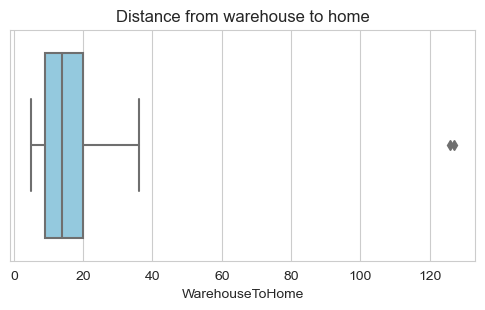

In [11]:
# Look at one column with a lot of outliers
plt.figure(figsize=(6, 3))
sns.boxplot(x=df["WarehouseToHome"], color="skyblue")
plt.title("Distance from warehouse to home")
plt.show()

In [12]:
#Define X, y, numerical and categorical columns
target = "Churn"

X = df.drop(columns=[target])           # predictors (inputs)
y = df[target]                          # target (what we predict)

numeric_cols = X.select_dtypes(include="number").columns.tolist()
categorical_cols = [c for c in X.columns if c not in numeric_cols]

print("Numerical  :", numeric_cols)
print()
print("Categorical:", categorical_cols)

Numerical  : ['Tenure', 'CityTier', 'WarehouseToHome', 'HourSpendOnApp', 'NumberOfDeviceRegistered', 'SatisfactionScore', 'NumberOfAddress', 'Complain', 'OrderAmountHikeFromlastYear', 'CouponUsed', 'OrderCount', 'DaySinceLastOrder', 'CashbackAmount']

Categorical: ['PreferredLoginDevice', 'PreferredPaymentMode', 'Gender', 'PreferedOrderCat', 'MaritalStatus']


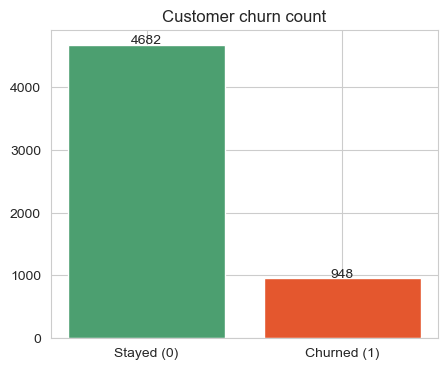

Churn rate = 16.8%


In [13]:
# How many customers churn?
counts = df["Churn"].value_counts().sort_index()

plt.figure(figsize=(5, 4))
plt.bar(["Stayed (0)", "Churned (1)"], counts.values, color=["#4C9F70", "#E4572E"])
plt.title("Customer churn count")
for i, v in enumerate(counts.values):
    plt.text(i, v + 20, str(v), ha="center")
plt.show()

print(f"Churn rate = {df['Churn'].mean() * 100:.1f}%")

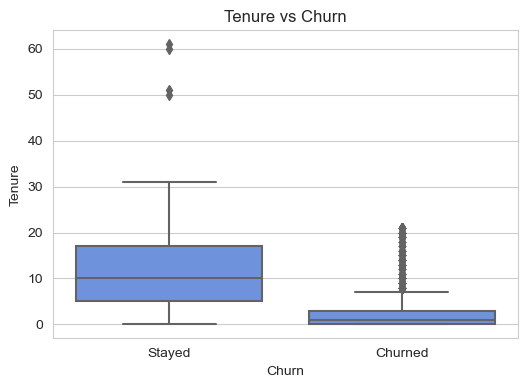

Churn
0    10.0
1     1.0
Name: Tenure, dtype: float64


In [14]:
# Tenure (months with the company) for churned vs stayed customers
plt.figure(figsize=(6, 4))
sns.boxplot(x="Churn", y="Tenure", data=df, color="#5B8DEF")
plt.xticks([0, 1], ["Stayed", "Churned"])
plt.title("Tenure vs Churn")
plt.show()

print(df.groupby("Churn")["Tenure"].median())

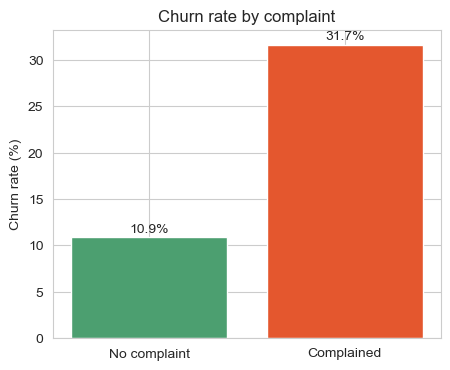

In [15]:
# Churn rate for customers who complained vs did not
rate = df.groupby("Complain")["Churn"].mean() * 100

plt.figure(figsize=(5, 4))
plt.bar(["No complaint", "Complained"], rate.values, color=["#4C9F70", "#E4572E"])
plt.ylabel("Churn rate (%)")
plt.title("Churn rate by complaint")
for i, v in enumerate(rate.values):
    plt.text(i, v + 0.5, f"{v:.1f}%", ha="center")
plt.show()

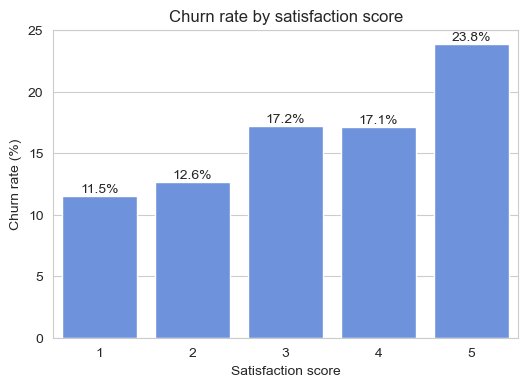

In [16]:
#Churn rate for each satisfaction score (1 = low, 5 = high)
rate = df.groupby("SatisfactionScore")["Churn"].mean() * 100

plt.figure(figsize=(6, 4))
ax = sns.barplot(x=rate.index, y=rate.values, color="#5B8DEF")
ax.set_xlabel("Satisfaction score")
ax.set_ylabel("Churn rate (%)")
ax.set_title("Churn rate by satisfaction score")
for i, v in enumerate(rate.values):
    ax.text(i, v + 0.3, f"{v:.1f}%", ha="center")
plt.show()

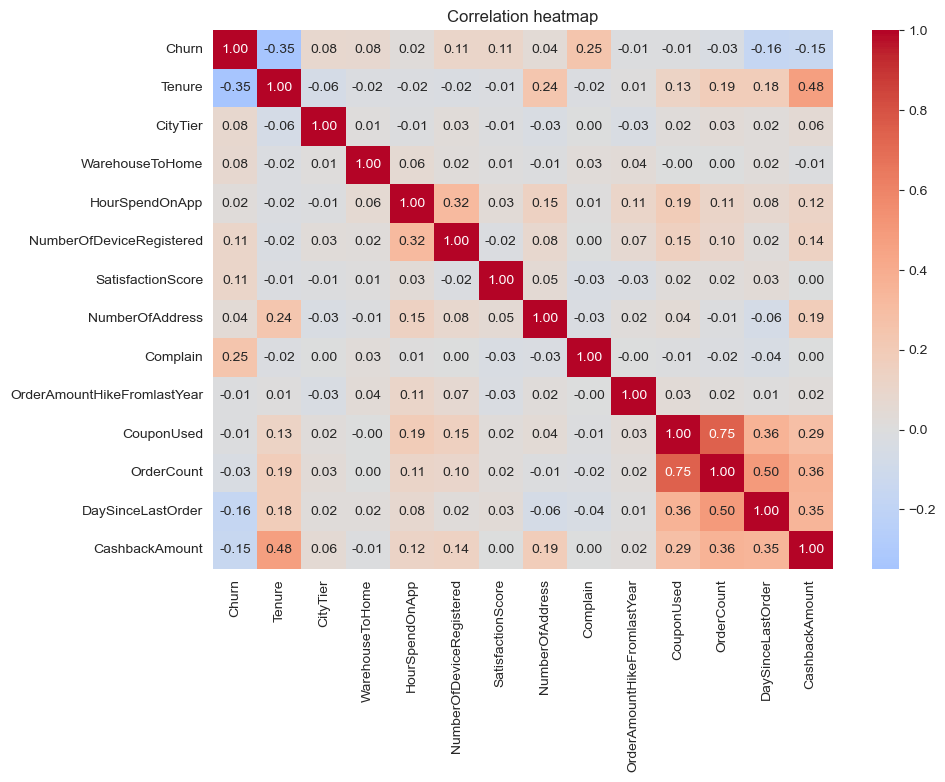

Tenure                        -0.35
Complain                       0.25
DaySinceLastOrder             -0.16
CashbackAmount                -0.15
NumberOfDeviceRegistered       0.11
SatisfactionScore              0.11
CityTier                       0.08
WarehouseToHome                0.08
NumberOfAddress                0.04
OrderCount                    -0.03
HourSpendOnApp                 0.02
OrderAmountHikeFromlastYear   -0.01
CouponUsed                    -0.01
Name: Churn, dtype: float64

In [17]:
#Correlation heatmap (how strongly numbers move together)
plt.figure(figsize=(10, 7))
corr = df.select_dtypes(include="number").corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap")
plt.show()

# Which numeric columns relate most to Churn?
corr["Churn"].drop("Churn").sort_values(key=abs, ascending=False).round(2)

In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,       # 20% kept aside for testing
    random_state=42,     # same split every time you run
    stratify=y           # keep the same churn % in train and test
)

print("Training rows:", X_train.shape[0])
print("Testing rows :", X_test.shape[0])
print("Churn % in train:", round(y_train.mean() * 100, 1))
print("Churn % in test :", round(y_test.mean() * 100, 1))

Training rows: 4504
Testing rows : 1126
Churn % in train: 16.8
Churn % in test : 16.9


In [21]:
#Preprocessing
def build_preprocessor(num_cols, cat_cols):
    """Prepares numbers and text columns so the model can use them."""
    num_steps = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),   # fill blanks with the median
        ("scaler", StandardScaler()),                    # put numbers on the same scale
    ])
    cat_steps = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),     # fill blanks with the most common value
        ("onehot", OneHotEncoder(handle_unknown="ignore")),       # text -> 0/1 columns
    ])
    return ColumnTransformer([
        ("num", num_steps, num_cols),
        ("cat", cat_steps, cat_cols),
    ])

In [22]:
#Train all three models and collect the scores
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, min_samples_leaf=2,
                                            class_weight="balanced", random_state=42, n_jobs=-1),
}

results = []
trained = {}

for name, clf in models.items():
    pipe = Pipeline([
        ("prep", build_preprocessor(numeric_cols, categorical_cols)),
        ("model", clf),
    ])
    pipe.fit(X_train, y_train)            # learn from the training data
    pred = pipe.predict(X_test)           # predict on unseen data
    trained[name] = pipe
    results.append({
        "Model": name,
        "Accuracy":  accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall":    recall_score(y_test, pred),
        "F1 Score":  f1_score(y_test, pred),
    })

results_df = pd.DataFrame(results).set_index("Model").round(3)
results_df

,Accuracy,Precision,Recall,F1 Score
Model,,,,
Logistic Regression,0.792,0.440,0.847,0.579
Decision Tree,0.838,0.513,0.837,0.636
Random Forest,0.966,0.918,0.879,0.898


              precision    recall  f1-score   support

      Stayed       0.98      0.98      0.98       936
     Churned       0.92      0.88      0.90       190

    accuracy                           0.97      1126
   macro avg       0.95      0.93      0.94      1126
weighted avg       0.97      0.97      0.97      1126



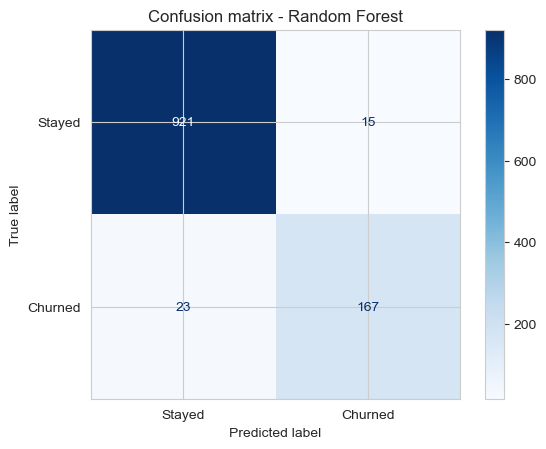

Correctly found churners (TP): 167
Churners we MISSED (FN)      : 23
Loyal customers wrongly flagged (FP): 15
Correctly identified loyal (TN): 921


In [23]:
#Classification report and confusion matrix
best_name = "Random Forest"          # change if another model wins on YOUR results
best_model = trained[best_name]
y_pred = best_model.predict(X_test)

print(classification_report(y_test, y_pred, target_names=["Stayed", "Churned"]))

cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["Stayed", "Churned"]).plot(cmap="Blues")
plt.title(f"Confusion matrix - {best_name}")
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"Correctly found churners (TP): {tp}")
print(f"Churners we MISSED (FN)      : {fn}")
print(f"Loyal customers wrongly flagged (FP): {fp}")
print(f"Correctly identified loyal (TN): {tn}")

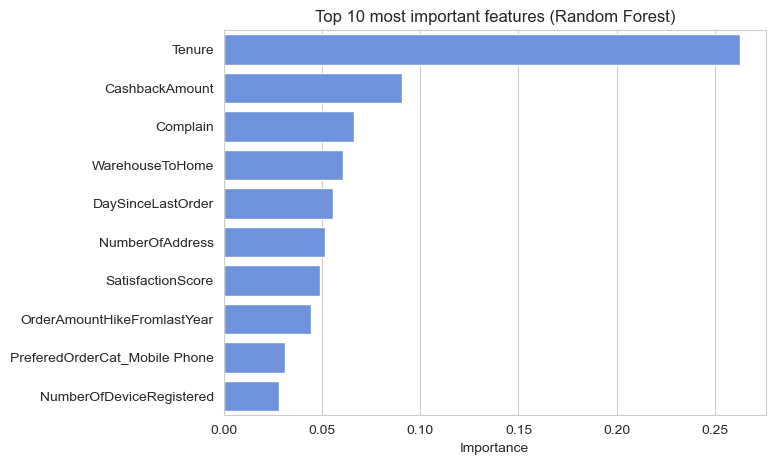

In [24]:
#Which Factors Matter Most? 
rf_pipe = trained["Random Forest"]
feature_names = rf_pipe.named_steps["prep"].get_feature_names_out()
importances = rf_pipe.named_steps["model"].feature_importances_

imp = (pd.Series(importances, index=feature_names)
         .sort_values(ascending=False)
         .head(10))
imp.index = [name.split("__")[1] for name in imp.index]   # remove "num__" / "cat__" prefix

plt.figure(figsize=(7, 5))
sns.barplot(x=imp.values, y=imp.index, color="#5B8DEF")
plt.title("Top 10 most important features (Random Forest)")
plt.xlabel("Importance")
plt.show()

In [27]:
#Final model with 10 inputs
final_num = ["Tenure", "CityTier", "WarehouseToHome", "SatisfactionScore",
             "NumberOfAddress", "Complain", "DaySinceLastOrder", "CashbackAmount"]
final_cat = ["PreferredPaymentMode", "MaritalStatus"]
final_features = final_num + final_cat

# Same split as before, but only with the chosen columns
X_train_f = X_train[final_features]
X_test_f = X_test[final_features]

final_model = Pipeline([
    ("prep", build_preprocessor(final_num, final_cat)),
    ("model", RandomForestClassifier(n_estimators=200, min_samples_leaf=2,
                                     class_weight="balanced", random_state=42, n_jobs=-1)),
])
final_model.fit(X_train_f, y_train)

pred_f = final_model.predict(X_test_f)
print("Accuracy :", round(accuracy_score(y_test, pred_f), 3))
print("Precision:", round(precision_score(y_test, pred_f), 3))
print("Recall   :", round(recall_score(y_test, pred_f), 3))
print("F1 Score :", round(f1_score(y_test, pred_f), 3))

Accuracy : 0.954
Precision: 0.845
Recall   : 0.889
F1 Score : 0.867


In [28]:
import os
import joblib

# Create data folder in the current working directory
os.makedirs("data", exist_ok=True)

# Save trained model in the current folder
joblib.dump(final_model, "model.pkl", compress=3)

# Save cleaned dataset inside the data folder
df.to_csv("data/dataset.csv", index=False)

# Check model size
print("Model size (MB):",
      round(os.path.getsize("model.pkl") / 1e6, 2))

print("Saved: model.pkl and data/dataset.csv")

Model size (MB): 3.26
Saved: model.pkl and data/dataset.csv


In [29]:
import joblib
import pandas as pd

# 1. Load the saved model from the current folder
loaded_model = joblib.load("model.pkl")

# 2. Create details for one new customer
new_customer = pd.DataFrame([{
    "Tenure": 2,
    "CityTier": 3,
    "WarehouseToHome": 25,
    "SatisfactionScore": 2,
    "NumberOfAddress": 4,
    "Complain": 1,
    "DaySinceLastOrder": 12,
    "CashbackAmount": 120,
    "PreferredPaymentMode": "Cash on Delivery",
    "MaritalStatus": "Single"
}])

# 3. Predict churn probability
prob = loaded_model.predict_proba(new_customer)[0][1]

# 4. Display the result
print(f"Churn probability: {prob:.1%}")

print("Prediction:", "Will churn" if prob >= 0.5 else "Will stay")

Churn probability: 51.8%
Prediction: Will churn


In [30]:
import sklearn

print("scikit-learn =", sklearn.__version__)

scikit-learn = 1.3.0
